## 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

sns.set_style("whitegrid")

In [2]:
df = pd.read_csv("exchange_rate.csv")
df["date"] = pd.to_datetime(df["date"], dayfirst=True, errors="coerce")
df["Ex_rate"] = pd.to_numeric(df["Ex_rate"], errors="coerce")

print(df.shape)
df.head()

(7588, 2)


,date,Ex_rate
0,1990-01-01,0.7855
1,1990-01-02,0.7818
2,1990-01-03,0.7867
3,1990-01-04,0.7860
4,1990-01-05,0.7849


## 2. Explore the data

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7588 entries, 0 to 7587
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   date     7588 non-null   datetime64[ns]
 1   Ex_rate  7588 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 118.7 KB


In [4]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate dates:", df["date"].duplicated().sum())
print("\nSummary statistics:")
df["Ex_rate"].describe()

Missing values:
date       0
Ex_rate    0
dtype: int64

Duplicate dates: 0

Summary statistics:


count    7588.000000
mean        0.776974
std         0.136620
min         0.483297
25%         0.701422
50%         0.761377
75%         0.873477
max         1.102536
Name: Ex_rate, dtype: float64

In [5]:
df = df.dropna(subset=["date", "Ex_rate"])
df = df.drop_duplicates(subset="date")
df = df.sort_values("date")

data = df.set_index("date")["Ex_rate"].asfreq("D")
data = data.interpolate()

print("Date range:", data.index.min(), "to", data.index.max())
print("Number of observations:", len(data))
print("Missing values after cleaning:", data.isnull().sum())

Date range: 1990-01-01 00:00:00 to 2010-10-10 00:00:00
Number of observations: 7588
Missing values after cleaning: 0


## 3. Visualize the exchange rate

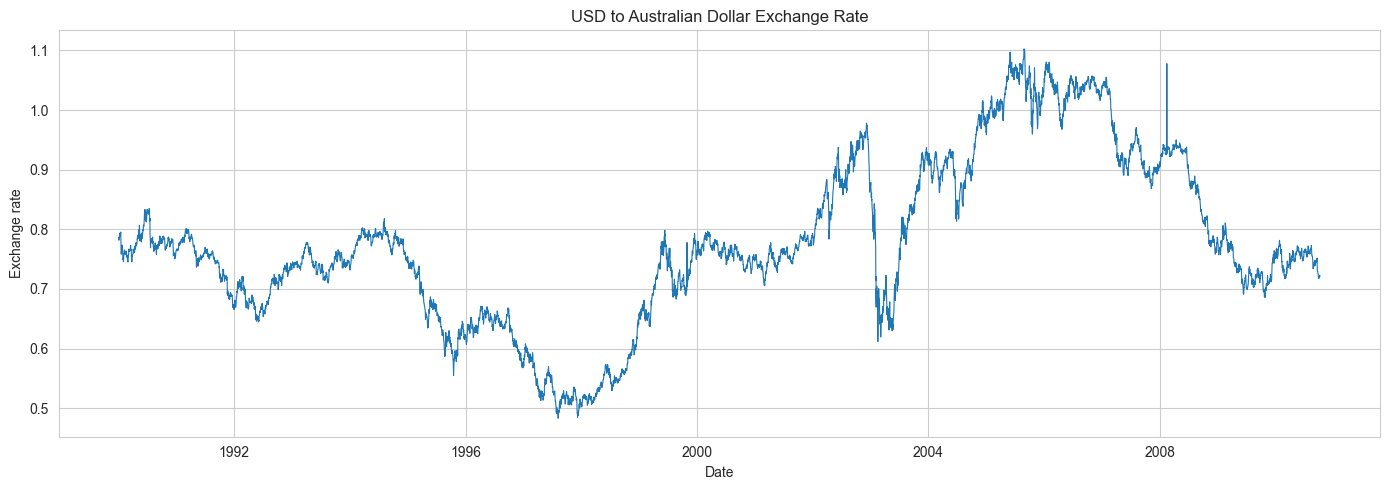

In [6]:
plt.figure(figsize=(14, 5))
plt.plot(data.index, data, linewidth=0.8)
plt.title("USD to Australian Dollar Exchange Rate")
plt.xlabel("Date")
plt.ylabel("Exchange rate")
plt.tight_layout()
plt.show()

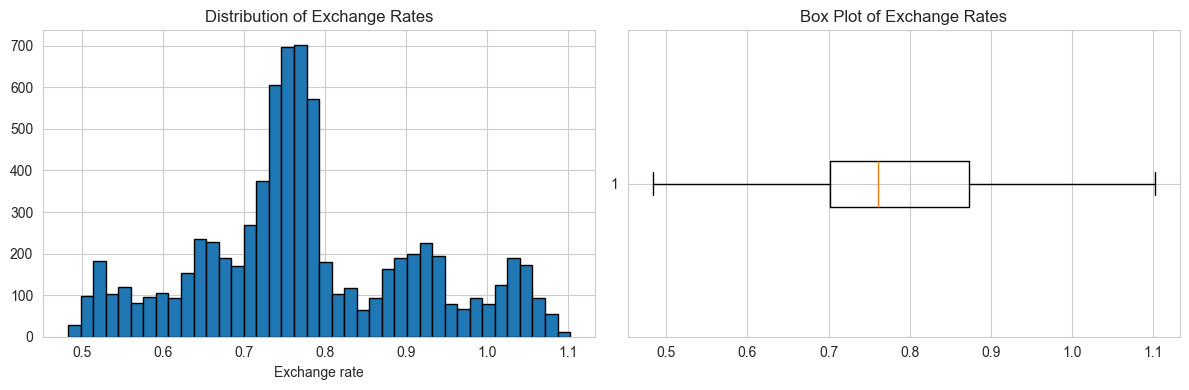

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(data.dropna(), bins=40, edgecolor="black")
axes[0].set_title("Distribution of Exchange Rates")
axes[0].set_xlabel("Exchange rate")
axes[1].boxplot(data.dropna().values, vert=False)
axes[1].set_title("Box Plot of Exchange Rates")
plt.tight_layout()
plt.show()

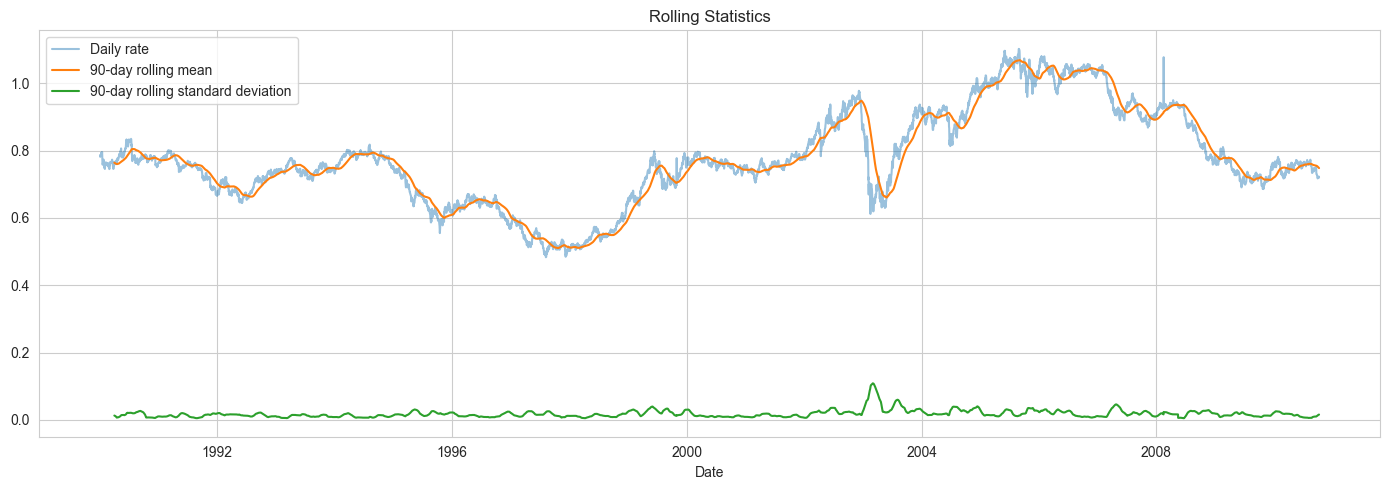

In [8]:
rolling_mean = data.rolling(90).mean()
rolling_std = data.rolling(90).std()

plt.figure(figsize=(14, 5))
plt.plot(data, label="Daily rate", alpha=0.45)
plt.plot(rolling_mean, label="90-day rolling mean")
plt.plot(rolling_std, label="90-day rolling standard deviation")
plt.title("Rolling Statistics")
plt.xlabel("Date")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Prepare training and testing data

In [9]:
test_size = int(len(data) * 0.2)
train = data.iloc[:-test_size]
test = data.iloc[-test_size:]

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Training observations: 6071
Testing observations: 1517
Training period: 1990-01-01 00:00:00 to 2006-08-15 00:00:00
Testing period: 2006-08-16 00:00:00 to 2010-10-10 00:00:00


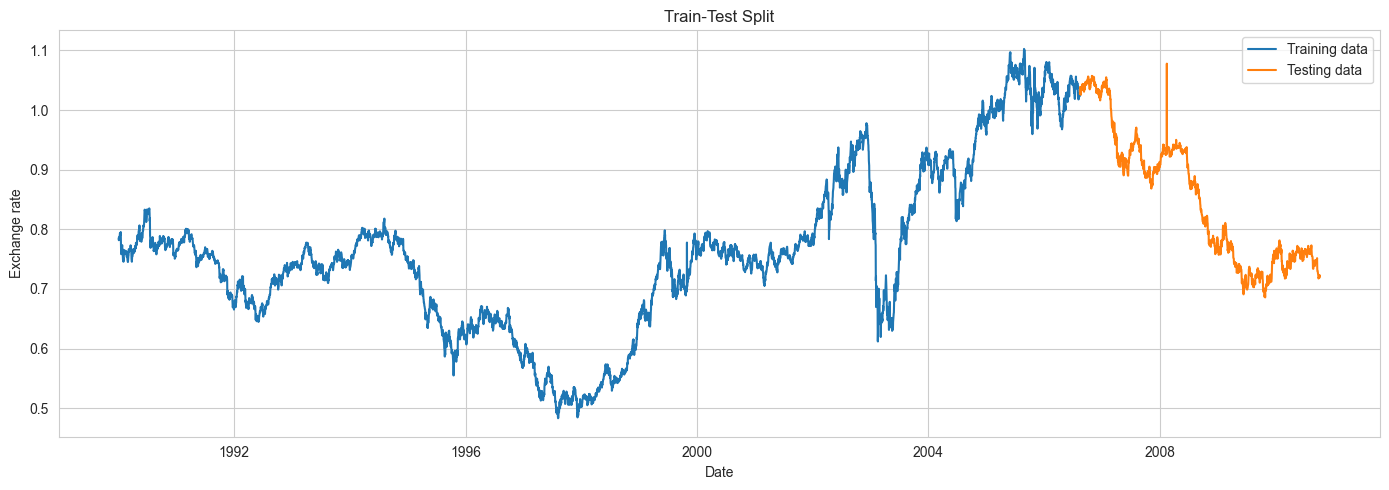

In [10]:
plt.figure(figsize=(14, 5))
plt.plot(train, label="Training data")
plt.plot(test, label="Testing data")
plt.title("Train-Test Split")
plt.xlabel("Date")
plt.ylabel("Exchange rate")
plt.legend()
plt.tight_layout()
plt.show()

## 5. ACF and PACF plots

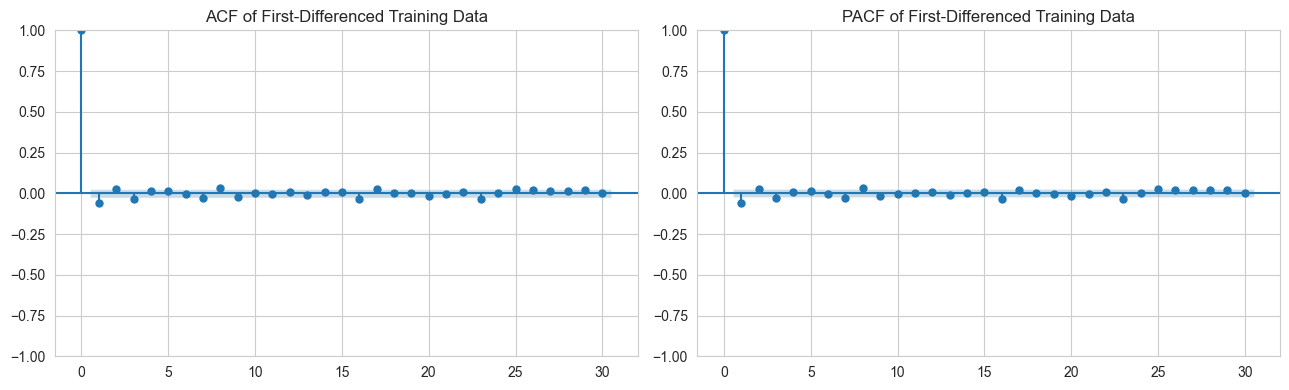

In [11]:
train_diff = train.diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(train_diff, lags=30, ax=axes[0])
axes[0].set_title("ACF of First-Differenced Training Data")
plot_pacf(train_diff, lags=30, method="ywm", ax=axes[1])
axes[1].set_title("PACF of First-Differenced Training Data")
plt.tight_layout()
plt.show()

## 6. Fit the ARIMA model

In [12]:
arima_model = ARIMA(train, order=(1, 1, 1), enforce_stationarity=False, enforce_invertibility=False)
arima_fit = arima_model.fit()

print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                Ex_rate   No. Observations:                 6071
Model:                 ARIMA(1, 1, 1)   Log Likelihood               22715.198
Date:                Mon, 12 Oct 2026   AIC                         -45424.397
Time:                        14:23:37   BIC                         -45404.265
Sample:                    01-01-1990   HQIC                        -45417.410
                         - 08-15-2006                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5976      0.062     -9.669      0.000      -0.719      -0.476
ma.L1          0.5402      0.064      8.448      0.000       0.415       0.666
sigma2      3.281e-05   1.95e-07    168.159      0.0

## 7. Check ARIMA residuals

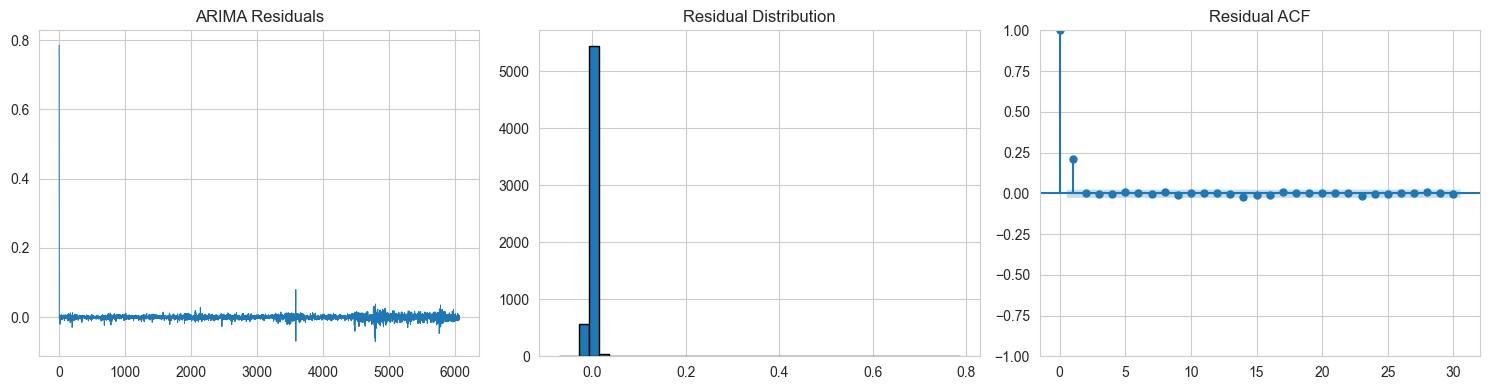

In [13]:
arima_resid = pd.Series(arima_fit.resid).dropna()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(arima_resid.values, linewidth=0.7)
axes[0].set_title("ARIMA Residuals")
axes[1].hist(arima_resid, bins=40, edgecolor="black")
axes[1].set_title("Residual Distribution")
plot_acf(arima_resid, lags=30, ax=axes[2])
axes[2].set_title("Residual ACF")
plt.tight_layout()
plt.show()

In [14]:
ljung_box_result = acorr_ljungbox(arima_resid, lags=[10, 20], return_df=True)
ljung_box_result

,lb_stat,lb_pvalue
10,267.629653,1.056436e-51
20,272.718900,2.895107e-46


## 8. Forecast with ARIMA

In [15]:
arima_forecast_result = arima_fit.get_forecast(steps=len(test))
arima_forecast = pd.Series(arima_forecast_result.predicted_mean.to_numpy(), index=test.index)
arima_conf_int = arima_forecast_result.conf_int()
arima_forecast.head()

date
2006-08-16    1.025172
2006-08-17    1.025276
2006-08-18    1.025214
2006-08-19    1.025251
2006-08-20    1.025229
Freq: D, dtype: float64

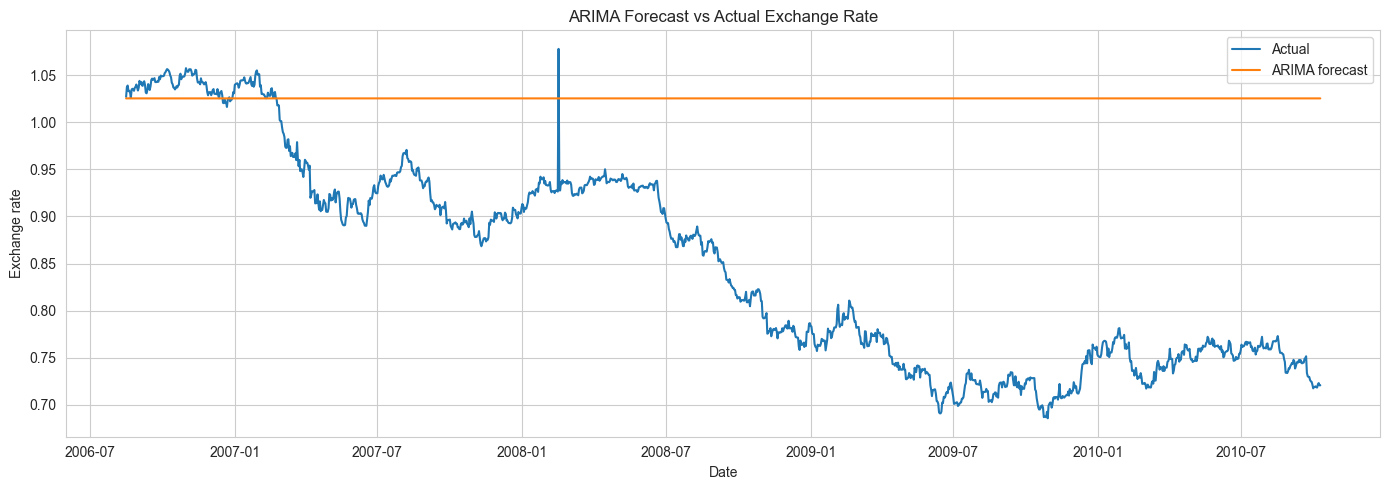

In [16]:
plt.figure(figsize=(14, 5))
plt.plot(test, label="Actual")
plt.plot(arima_forecast, label="ARIMA forecast")
plt.title("ARIMA Forecast vs Actual Exchange Rate")
plt.xlabel("Date")
plt.ylabel("Exchange rate")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Fit Exponential Smoothing

In [17]:
es_model = ExponentialSmoothing(
    train,
    trend="add",
    damped_trend=True,
    seasonal=None,
    initialization_method="estimated"
)
es_fit = es_model.fit(optimized=True)
print(es_fit.summary())

                       ExponentialSmoothing Model Results                       
Dep. Variable:                  Ex_rate   No. Observations:                 6071
Model:             ExponentialSmoothing   SSE                              0.199
Optimized:                         True   AIC                         -62665.294
Trend:                         Additive   BIC                         -62631.738
Seasonal:                          None   AICC                        -62665.276
Seasonal Periods:                  None   Date:                 Mon, 12 Oct 2026
Box-Cox:                          False   Time:                         14:23:39
Box-Cox Coeff.:                    None                                         
                       coeff                 code              optimized      
------------------------------------------------------------------------------
smoothing_level            0.9411474                alpha                 True
smoothing_trend            0.00181

## 10. Forecast with Exponential Smoothing

In [18]:
es_forecast = pd.Series(es_fit.forecast(len(test)).to_numpy(), index=test.index)
es_forecast.head()

date
2006-08-16    1.025226
2006-08-17    1.025213
2006-08-18    1.025200
2006-08-19    1.025187
2006-08-20    1.025175
Freq: D, dtype: float64

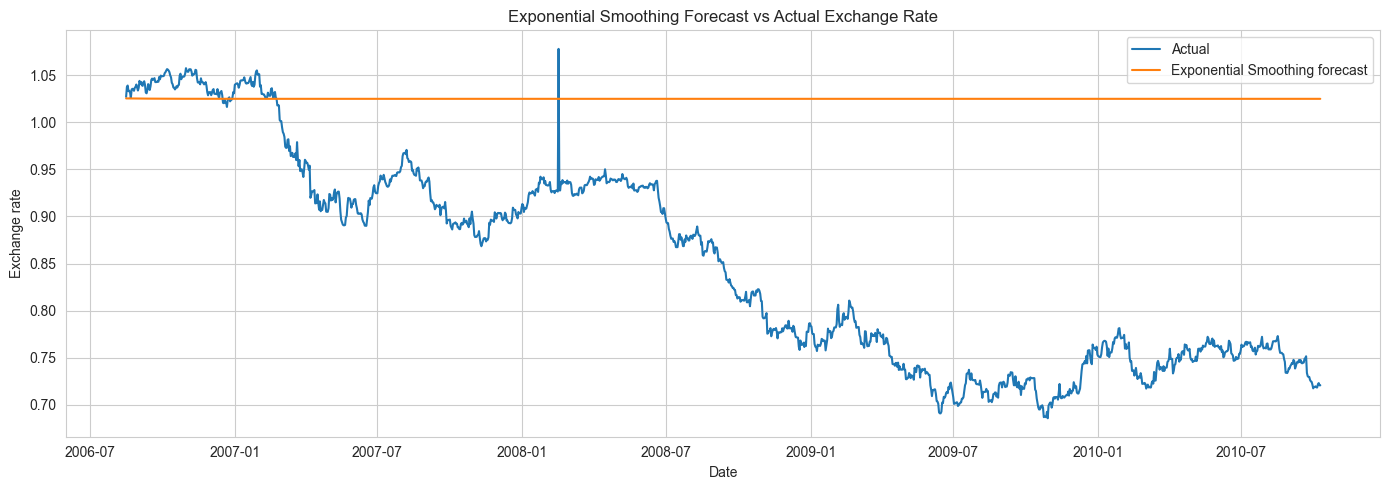

In [19]:
plt.figure(figsize=(14, 5))
plt.plot(test, label="Actual")
plt.plot(es_forecast, label="Exponential Smoothing forecast")
plt.title("Exponential Smoothing Forecast vs Actual Exchange Rate")
plt.xlabel("Date")
plt.ylabel("Exchange rate")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Compare forecast accuracy

In [20]:
def forecast_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE (%)": mean_absolute_percentage_error(actual, predicted) * 100
    }

results = pd.DataFrame({
    "ARIMA": forecast_metrics(test, arima_forecast),
    "Exponential Smoothing": forecast_metrics(test, es_forecast)
}).T

results

,MAE,RMSE,MAPE (%)
ARIMA,0.179041,0.206861,22.967278
Exponential Smoothing,0.178677,0.206465,22.921365


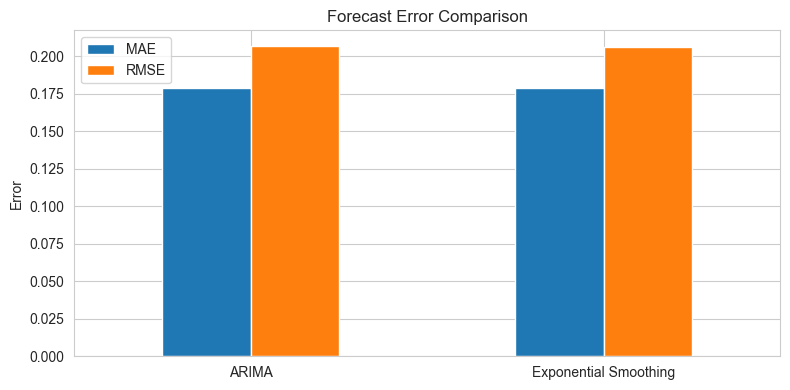

In [21]:
plt.figure(figsize=(8, 4))
results[["MAE", "RMSE"]].plot(kind="bar", ax=plt.gca())
plt.title("Forecast Error Comparison")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [22]:
best_model = results["RMSE"].idxmin()
print("Model with the lower RMSE:", best_model)
print()
print("ARIMA metrics:")
print(results.loc["ARIMA"])
print()
print("Exponential Smoothing metrics:")
print(results.loc["Exponential Smoothing"])

Model with the lower RMSE: Exponential Smoothing

ARIMA metrics:
MAE          0.179041
RMSE         0.206861
MAPE (%)    22.967278
Name: ARIMA, dtype: float64

Exponential Smoothing metrics:
MAE          0.178677
RMSE         0.206465
MAPE (%)    22.921365
Name: Exponential Smoothing, dtype: float64


## 12. Forecast the next 30 days

In [23]:
if best_model == "ARIMA":
    final_fit = ARIMA(data, order=(1, 1, 1), enforce_stationarity=False, enforce_invertibility=False).fit()
    future_values = final_fit.forecast(steps=30)
else:
    final_fit = ExponentialSmoothing(
        data,
        trend="add",
        damped_trend=True,
        seasonal=None,
        initialization_method="estimated"
    ).fit(optimized=True)
    future_values = final_fit.forecast(30)

future_index = pd.date_range(data.index[-1] + pd.Timedelta(days=1), periods=30, freq="D")
future_forecast = pd.Series(np.asarray(future_values), index=future_index, name="Forecast")
future_forecast.head()

2010-10-11    0.720815
2010-10-12    0.720774
2010-10-13    0.720735
2010-10-14    0.720697
2010-10-15    0.720660
Freq: D, Name: Forecast, dtype: float64

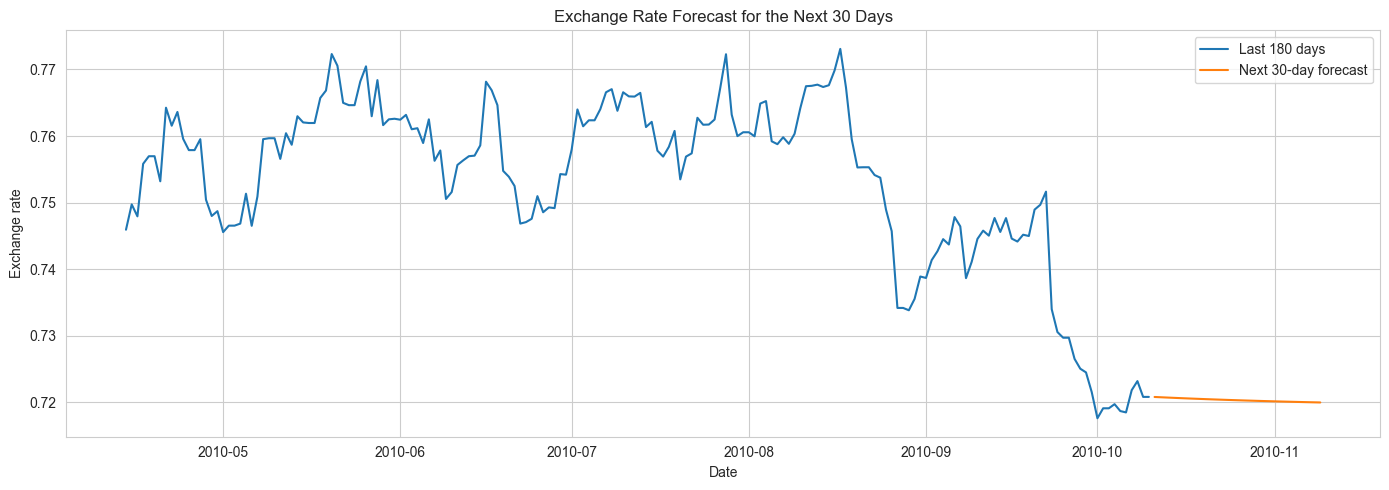

In [24]:
plt.figure(figsize=(14, 5))
plt.plot(data.iloc[-180:], label="Last 180 days")
plt.plot(future_forecast, label="Next 30-day forecast")
plt.title("Exchange Rate Forecast for the Next 30 Days")
plt.xlabel("Date")
plt.ylabel("Exchange rate")
plt.legend()
plt.tight_layout()
plt.show()

## 13. Conclusion

The models were compared using MAE, RMSE and MAPE on the same test period.
The model with the lower RMSE was: Exponential Smoothing
ARIMA models temporal dependence through autoregressive and moving-average terms.
Exponential Smoothing forecasts by updating level and trend based on recent observations.
The result may change with a different test period or parameter selection. Exchange rates can also be affected by economic events that are not included in this dataset.